In [1]:
def check_store_performance(revenue):
    if revenue >= 500000:
        return "High Performing"
    elif revenue >= 200000:
        return "Average Performing"
    else:
        return "Needs Improvement"

print(check_store_performance(350000))

Average Performing


In [2]:
# Dictionary containing store branch names and their weekly footfall
store_data = {
    "Branch_A": 1500,
    "Branch_B": 850,
    "Branch_C": 3200
}

# Looping through the dictionary to apply a conversion rate
conversion_rate = 0.05  # 5% of footfall results in a sale

print("Estimated Weekly Sales Transactions:")
for branch, footfall in store_data.items():
    estimated_sales = int(footfall * conversion_rate)
    print(f"{branch}: {estimated_sales} transactions")

Estimated Weekly Sales Transactions:
Branch_A: 75 transactions
Branch_B: 42 transactions
Branch_C: 160 transactions


In [3]:
import pandas as pd
import numpy as np

# Load a CSV file (replace 'superstore_sales.csv' with your actual file path)
# df = pd.read_csv('superstore_sales.csv')

# Creating mock retail data for immediate practice
data = {
    'Branch_ID': ['B1', 'B2', 'B1', 'B3', 'B2', 'B3'],
    'Region': ['North', 'South', 'North', 'East', 'South', 'East'],
    'Revenue': [50000, 75000, 60000, 45000, 80000, 55000],
    'Footfall': [1200, 1500, 1300, 900, 1600, 1100]
}
df = pd.DataFrame(data)
print("Original Dataset:\n", df.head())

Original Dataset:
   Branch_ID Region  Revenue  Footfall
0        B1  North    50000      1200
1        B2  South    75000      1500
2        B1  North    60000      1300
3        B3   East    45000       900
4        B2  South    80000      1600


In [4]:
import pandas as pd
import numpy as np

file_path = r"D:\Mim's Projects\Internship\superstore_sales.csv"
df = pd.read_csv(file_path)

# Display the first 5 rows to confirm it loaded successfully
print(df.head())

   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2017-152156  08/11/2017  11/11/2017    Second Class    CG-12520   
1       2  CA-2017-152156  08/11/2017  11/11/2017    Second Class    CG-12520   
2       3  CA-2017-138688  12/06/2017  16/06/2017    Second Class    DV-13045   
3       4  US-2016-108966  11/10/2016  18/10/2016  Standard Class    SO-20335   
4       5  US-2016-108966  11/10/2016  18/10/2016  Standard Class    SO-20335   

     Customer Name    Segment        Country             City       State  \
0      Claire Gute   Consumer  United States        Henderson    Kentucky   
1      Claire Gute   Consumer  United States        Henderson    Kentucky   
2  Darrin Van Huff  Corporate  United States      Los Angeles  California   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale     Florida   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale     Florida   

   Postal Code Region       Product ID         Cat

In [5]:
# 1. Filtering: rows where Sales are greater than 5000
high_sales_df = df[df['Sales'] > 5000]

# 2. Sorting: filtered data by Sales in descending order
sorted_df = high_sales_df.sort_values(by='Sales', ascending=False)

# 3. Grouping: Group by Region to see the total sales per region
regional_sales = df.groupby('Region')['Sales'].sum().reset_index()

print("\nTotal Sales by Region:\n", regional_sales)


Total Sales by Region:
     Region        Sales
0  Central  492646.9132
1     East  669518.7260
2    South  389151.4590
3     West  710219.6845


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Missing Data Handling
print("Missing values before cleaning:\n", df.isnull().sum())

# Dropping rows with missing values (or df.fillna(0) to replace them)
df_clean = df.dropna() 
print("\nMissing values after cleaning:\n", df_clean.isnull().sum())

Missing values before cleaning:
 Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64

Missing values after cleaning:
 Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
dtype: int64


C:\Users\91877\AppData\Local\Temp\ipykernel_25376\1626342521.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Category', y='Sales', data=category_sales, palette='viridis')


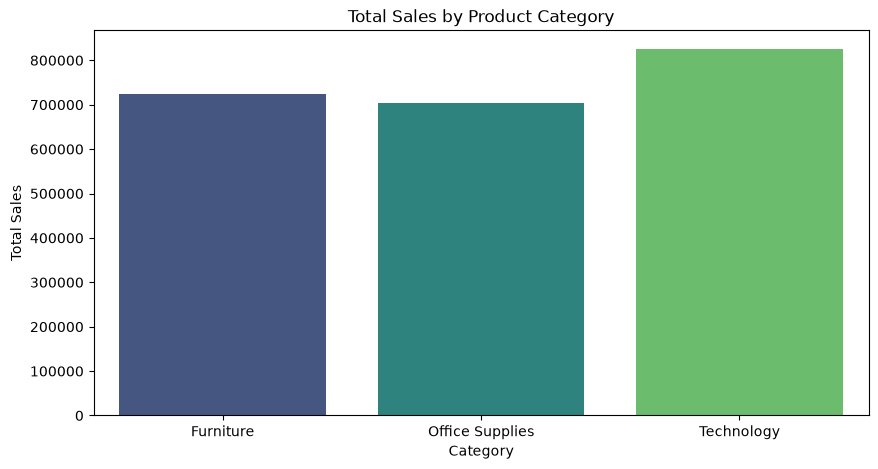

In [8]:
plt.figure(figsize=(10, 5))
# Assuming the dataset has 'Category' and 'Sales' columns
category_sales = df_clean.groupby('Category')['Sales'].sum().reset_index()
sns.barplot(x='Category', y='Sales', data=category_sales, palette='viridis')
plt.title('Total Sales by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.show()

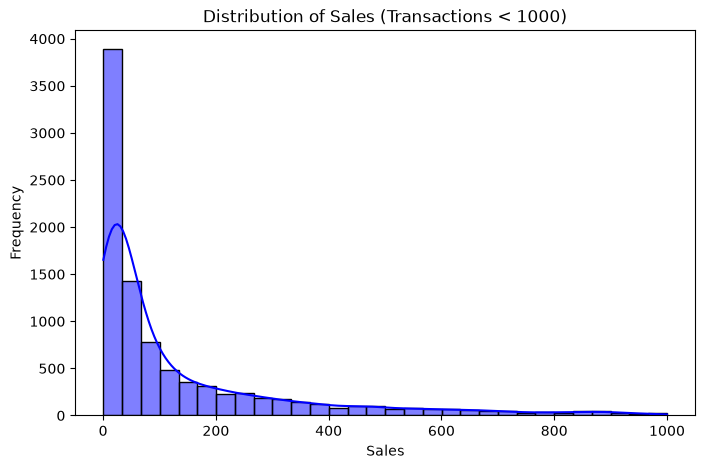

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(df_clean[df_clean['Sales'] < 1000]['Sales'], bins=30, kde=True, color='blue')
plt.title('Distribution of Sales (Transactions < 1000)')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.show()

In [10]:
# Scatter Plot
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Discount', y='Profit', data=df_clean, color='red', alpha=0.5)
plt.title('Impact of Discount on Profit')
plt.xlabel('Discount')
plt.ylabel('Profit')
plt.show()

# Correlation Analysis (Heatmap)
plt.figure(figsize=(8, 6))
# Select only numerical columns for correlation
numerical_cols = df_clean.select_dtypes(include=['float64', 'int64'])
correlation_matrix = numerical_cols.corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Superstore Variables')
plt.show()

ValueError: Could not interpret value `Discount` for `x`. An entry with this name does not appear in `data`.

<Figure size 800x500 with 0 Axes>

In [11]:
# Check exact column names
print(df_clean.columns)

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales'],
      dtype='str')


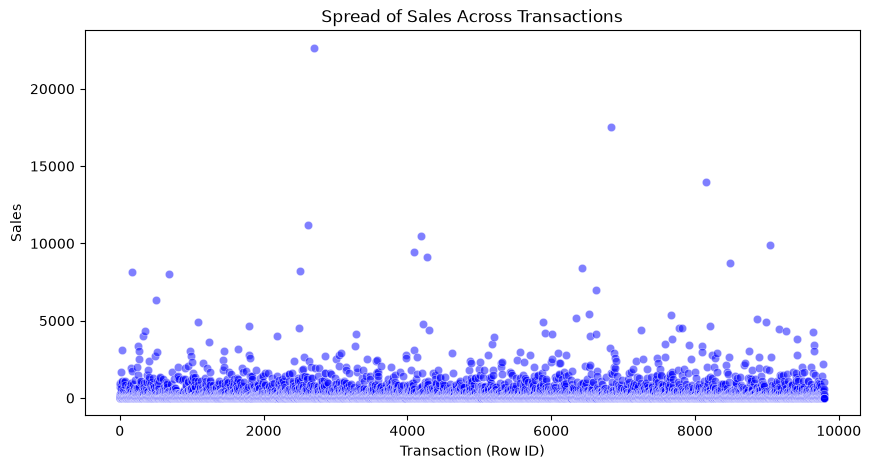

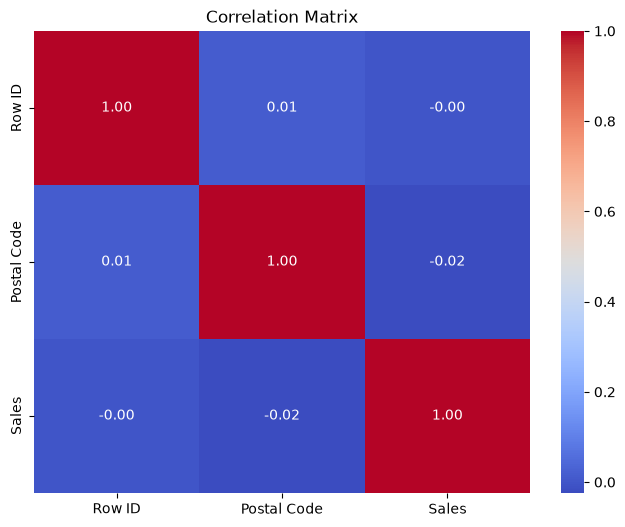

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Corrected Scatter Plot (Using 'Row ID' and 'Sales')
plt.figure(figsize=(10, 5))
sns.scatterplot(x='Row ID', y='Sales', data=df_clean, color='blue', alpha=0.5)
plt.title('Spread of Sales Across Transactions')
plt.xlabel('Transaction (Row ID)')
plt.ylabel('Sales')
plt.show()

# 2. Corrected Correlation Analysis (Heatmap)
plt.figure(figsize=(8, 6))
# Selecting only the numerical columns available in your dataset
numerical_cols = df_clean[['Row ID', 'Postal Code', 'Sales']]
correlation_matrix = numerical_cols.corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd

X = pd.get_dummies(df_clean[['Category', 'Region']], drop_first=True)
y = df_clean['Sales']

# 2. Dataset split into training and testing (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Implementation of Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Predictions and results
predictions = model.predict(X_test)
print("Model Training Complete.\n")
print(f"R-squared Score: {r2_score(y_test, predictions):.4f}")
print("Sample Predictions vs Actual Sales:")
results = pd.DataFrame({'Actual Sales': y_test, 'Predicted Sales': predictions})
print(results.head())

Model Training Complete.

R-squared Score: 0.0476
Sample Predictions vs Actual Sales:
      Actual Sales  Predicted Sales
8962       273.960       355.797213
7138        62.880       123.298199
4709        11.680       107.413548
6204         7.712       359.619212
6901      2399.960       429.007144
